### Projektüberblick & Datensatzbeschreibung

In diesem Projekt wird ein Regressionsmodell entwickelt, um die elektrische Reichweite pro Kilowattstunde (Reichweite_pro_kWh) von Elektrofahrzeugen vorherzusagen. 

#### Datensatzbeschreibung

Der zugrunde liegende Datensatz besteht aus meistens metrische Daten mehrerer Elektrofahrzeuge (Schulbusse, ÖPNV in den USA) und enthält zahlreiche Messgrößen pro Fahrt. Die wichtigsten Spalten des Datensatzes sind:

- **Vehicle ID** – eindeutige Fahrzeugkennung (String ID)
- **Total Distance** – gesamte gefahrene Strecke (in Meilen)
- **Driving Time / Idling Time** – Fahr- und Leerlaufzeit (in Stunden)
- **Total Run Time** – Gesamtdauer der Fahrt (in Stunden)
- **SOC Used** – verbrauchter Ladezustand (%)
- **Total Energy Consumption** – gesamte Energieverbrauch (in kWh)
- **Average Speed** – durchschnittliche Fahrgeschwindigkeit (mph Meilen pro Stunde)
- **Average Ambient Temperature** – durchschnittliche Umgebungstemperatur (Fahrenheit)

Basierend auf diesen Spalten wurden zusätzliche Merkmale konstruiert, z. B.:

- **Reichweite_pro_kWh** – berechnet als Strecke geteilt durch Energieverbrauch (Meilen pro KWh)
- **Driving Time %** – Anteil der Fahrzeit an der Gesamtlaufzeit (%)

Zielvariable ist **Reichweite_pro_kWh**, welche die Effizienz des Fahrzeugs pro Energieeinheit beschreibt. Die Vorhersage dieses Werts ermöglicht Rückschlüsse auf Fahrverhalten, Fahrzeugzustand oder Umwelteinflüsse.

# Datensatz Laden

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV 
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

from pathlib import Path

df = pd.read_csv("data/all_fused_vehicle_data.csv")
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19922 entries, 0 to 19921
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Vehicle ID                             19922 non-null  object 
 1   Local Trip Start Time                  7448 non-null   object 
 2   Local Trip End Time                    7448 non-null   object 
 3   Total Distance                         19899 non-null  float64
 4   Idling Time                            18335 non-null  float64
 5   Driving Time                           19134 non-null  float64
 6   Total Run Time                         19077 non-null  float64
 7   Initial SOC                            11440 non-null  float64
 8   Final SOC                              11441 non-null  float64
 9   SOC Used                               17957 non-null  float64
 10  Total Energy Consumption               17519 non-null  float64
 11  Av

Vehicle ID                                   0
Local Trip Start Time                    12474
Local Trip End Time                      12474
Total Distance                              23
Idling Time                               1587
Driving Time                               788
Total Run Time                             845
Initial SOC                               8482
Final SOC                                 8481
SOC Used                                  1965
Total Energy Consumption                  2403
Average Ambient Temperature                208
Initial Odometer                          4785
Final Odometer                            2760
Percent Idling Time                       6731
Drive Cycle                              19922
Average Speed                             7832
Date                                      7448
Number of Trips                          17305
Max SOC                                  12030
Min SOC                                  12030
Energy Consum

# NaN Werte Behandeln
In diesem Schritt werden bei NaN Werte für die ausgewählte Spalten die komplette Zeile aus dem Dataframe imputiert. Bei Größe Zahl an NaN Werten wird es nicht sinnvoll angesehen die Werte durch Median oder Mean zu tauschen

In [ ]:
required_cols = [

    "Initial SOC",
    "Idling Time",
    "Driving Time",
    "Total Distance",
    "Final SOC",
    "SOC Used",
    "Average Speed",
    "Average Ambient Temperature",
    "Total Energy Consumption"
]

# Drop rows with missing values in any of the specified columns
df_cleaned = df.dropna(subset=required_cols)

#df_cleaned.to_csv("cleaned_vehicle_ev.csv", index=False)

df_cleaned.info()
df_cleaned.describe()
df_cleaned.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
Index: 6875 entries, 0 to 15371
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Vehicle ID                             6875 non-null   object 
 1   Local Trip Start Time                  5763 non-null   object 
 2   Local Trip End Time                    5763 non-null   object 
 3   Total Distance                         6875 non-null   float64
 4   Idling Time                            6875 non-null   float64
 5   Driving Time                           6875 non-null   float64
 6   Total Run Time                         6875 non-null   float64
 7   Initial SOC                            6875 non-null   float64
 8   Final SOC                              6875 non-null   float64
 9   SOC Used                               6875 non-null   float64
 10  Total Energy Consumption               6875 non-null   float64
 11  Average 

Vehicle ID                                  0
Local Trip Start Time                    1112
Local Trip End Time                      1112
Total Distance                              0
Idling Time                                 0
Driving Time                                0
Total Run Time                              0
Initial SOC                                 0
Final SOC                                   0
SOC Used                                    0
Total Energy Consumption                    0
Average Ambient Temperature                 0
Initial Odometer                            0
Final Odometer                              0
Percent Idling Time                         0
Drive Cycle                              6875
Average Speed                               0
Date                                     5763
Number of Trips                          6875
Max SOC                                  2406
Min SOC                                  2406
Energy Consumed While Driving     

Jetzt neuer Datenrahmen mit den ausgewählten Spalten zur weiteren Verarbeitung. Die Variable “Total Distance„ wird erst ab einem Wert von 2 Meilen berücksichtigt, da eine Fahrt von weniger als 2 Meilen zu kurz ist und unplausible Werte für den Energieverbrauch ergeben kann. Eine weitere Abgrenzung von sogenannten Corner Cases erfolgt durch die Abgrenzung des „Total Energy Consumption“ zwischen 1 KWh und 500KWh. Ein Verbrauch unter 1 KWh ist zu gering, um Rückschlüsse auf die Reichweite zu ziehen und Werte über 500KWh an einem Tag erscheinen unplausibel und können auf einen Defekt am Fahrzeug oder eine Fehlmessung hinweisen.

Am Ende dieses Schritt bleiben 4001 Werte im DF übrig.

In [ ]:
# Define the list of complete columns you want to keep
selected_columns = [
    "Vehicle ID",
    "Total Distance",
    "Idling Time",
    "Driving Time",
    "Total Run Time",
    "Initial SOC",
    "Final SOC",
    "SOC Used",
    "Total Energy Consumption",
    "Average Ambient Temperature",
    "Initial Odometer",
    "Final Odometer",
    "Percent Idling Time",
    "Average Speed"
]
df_s = df_cleaned[selected_columns]

df_s = df_cleaned[
    (df_cleaned["Total Distance"] > 2) &
    (df_cleaned["Total Energy Consumption"] >= 1) & (df_cleaned["Total Energy Consumption"] <= 500)

][selected_columns]

#df_s.to_csv("Selected_df.csv", index=False)



print(df_s.shape)
df_s.info()
df_s.describe()
df_s.isnull().sum()
df_s.isna().sum()


(4001, 14)
<class 'pandas.core.frame.DataFrame'>
Index: 4001 entries, 0 to 15371
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Vehicle ID                   4001 non-null   object 
 1   Total Distance               4001 non-null   float64
 2   Idling Time                  4001 non-null   float64
 3   Driving Time                 4001 non-null   float64
 4   Total Run Time               4001 non-null   float64
 5   Initial SOC                  4001 non-null   float64
 6   Final SOC                    4001 non-null   float64
 7   SOC Used                     4001 non-null   float64
 8   Total Energy Consumption     4001 non-null   float64
 9   Average Ambient Temperature  4001 non-null   float64
 10  Initial Odometer             4001 non-null   float64
 11  Final Odometer               4001 non-null   float64
 12  Percent Idling Time          4001 non-null   float64
 13  Average Spe

Vehicle ID                     0
Total Distance                 0
Idling Time                    0
Driving Time                   0
Total Run Time                 0
Initial SOC                    0
Final SOC                      0
SOC Used                       0
Total Energy Consumption       0
Average Ambient Temperature    0
Initial Odometer               0
Final Odometer                 0
Percent Idling Time            0
Average Speed                  0
dtype: int64

# Vehicle ID
Um die unterschiedlichen Fahrzeuge im Datensatz zu analysieren, wurden zunächst alle eindeutigen Fahrzeug-IDs bestimmt. Dies liefert einen Überblick darüber, wie viele verschiedene Fahrzeuge in der Analyse berücksichtigt werden.

Anschließend wurde die Spalte **Vehicle ID** in numerische Werte umgewandelt (kodiert), da viele Machine-Learning-Modelle keine kategorialen Texteingaben verarbeiten können. Dafür wird erstmal eine einfache **Category-Encoding-Methode** verwendet, bei der jedem Fahrzeug ein eindeutiger Integer-Wert zugewiesen wurde.

In [5]:
eindeutige_Vehicles=print(df_s['Vehicle ID'].unique())
eindeutige_Vehicles_Anzahl=print(df_s['Vehicle ID'].nunique())

df_s["Vehicle ID (encoded)"] = df_s["Vehicle ID"].astype("category").cat.codes

['EV192' 'EV193' 'EV195' 'EV196' 'EV197' 'EV198' 'EV200' 'EV146' 'EV153'
 'EV154' 'EV155' 'EV156' 'EV157' 'EV158' 'EV159' 'EV161' 'EV162' 'EV163'
 'EV164' 'EV165' 'EV166' 'EV167' 'EV168' 'EV169' 'EV212' 'EV213' 'EV214'
 'EV215' 'EV216' 'EV217' 'EV218' 'EV219' 'EV220' 'EV221' 'EV065' 'EV066']
36


# Exploration Total Distance and Energy Consummption

count    4001.000000
mean      125.579555
std        96.339625
min         1.642857
25%        53.100000
50%        89.000000
75%       184.943630
max       497.486400
Name: Total Energy Consumption, dtype: float64


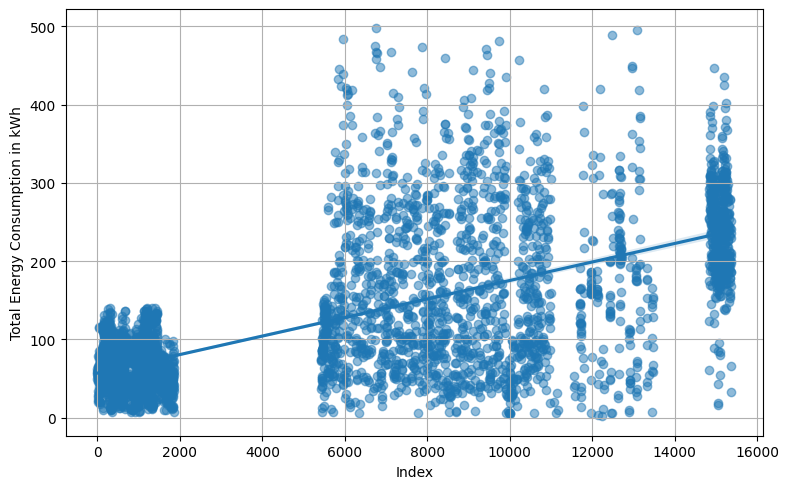

count    4001.000000
mean       53.885739
std        38.249182
min         2.100000
25%        26.000000
50%        39.000000
75%        77.777033
max       234.023925
Name: Total Distance, dtype: float64


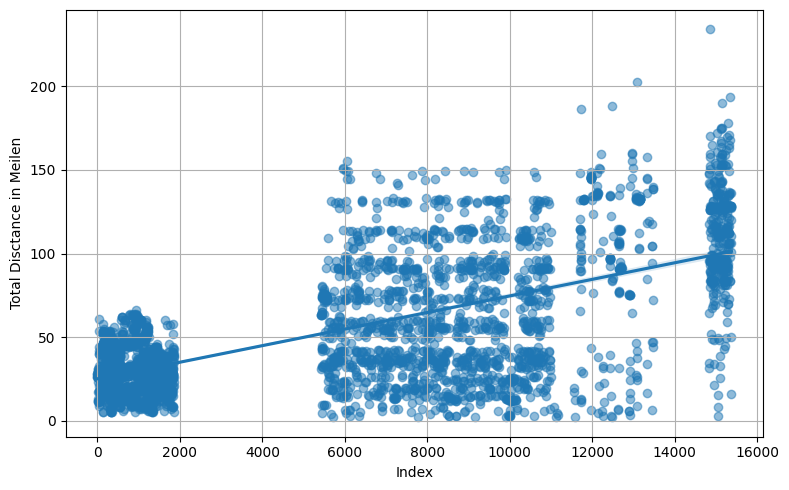

In [6]:
print(df_s["Total Energy Consumption"].describe())
plt.figure(figsize=(8, 5))
sns.regplot(x=df_s.index, y=df_s["Total Energy Consumption"], scatter_kws={'alpha': 0.5})
plt.xlabel("Index")
plt.ylabel("Total Energy Consumption in kWh")
plt.grid(True)
plt.tight_layout()
plt.show()


print(df_s["Total Distance"].describe())
plt.figure(figsize=(8, 5))
sns.regplot(x=df_s.index, y=df_s["Total Distance"], scatter_kws={'alpha': 0.5})
plt.xlabel("Index")
plt.ylabel("Total Disctance in Meilen")
plt.grid(True)
plt.tight_layout()
plt.show()

# Berechnung der Zielgröße Reichweite 
aus den "Total Distance" und "Total Energy Consumption"
# Berechnung des Features "Driving Time %"
Anteil Fahrzeit von der ganzen Fahrzeit.

In [7]:
df_s.loc[:, "Reichweite_pro_kWh"] = df_s["Total Distance"] / df_s["Total Energy Consumption"]
df_s.head()
print(df_s["Reichweite_pro_kWh"].describe())

df_s["Driving Time %"] = df_s["Driving Time"] / df_s["Total Run Time"] * 100

count    4001.000000
mean        0.466641
std         0.157502
min         0.059209
25%         0.368318
50%         0.440505
75%         0.541140
max         3.688696
Name: Reichweite_pro_kWh, dtype: float64


Hier folgt eine erste Visualisierung der Abhängigkeit zwischen der Zielvariable "Reichweite" und mehrerer anderer Variablen wie "Average Speed" oder "Average Ambient Temperatur"..

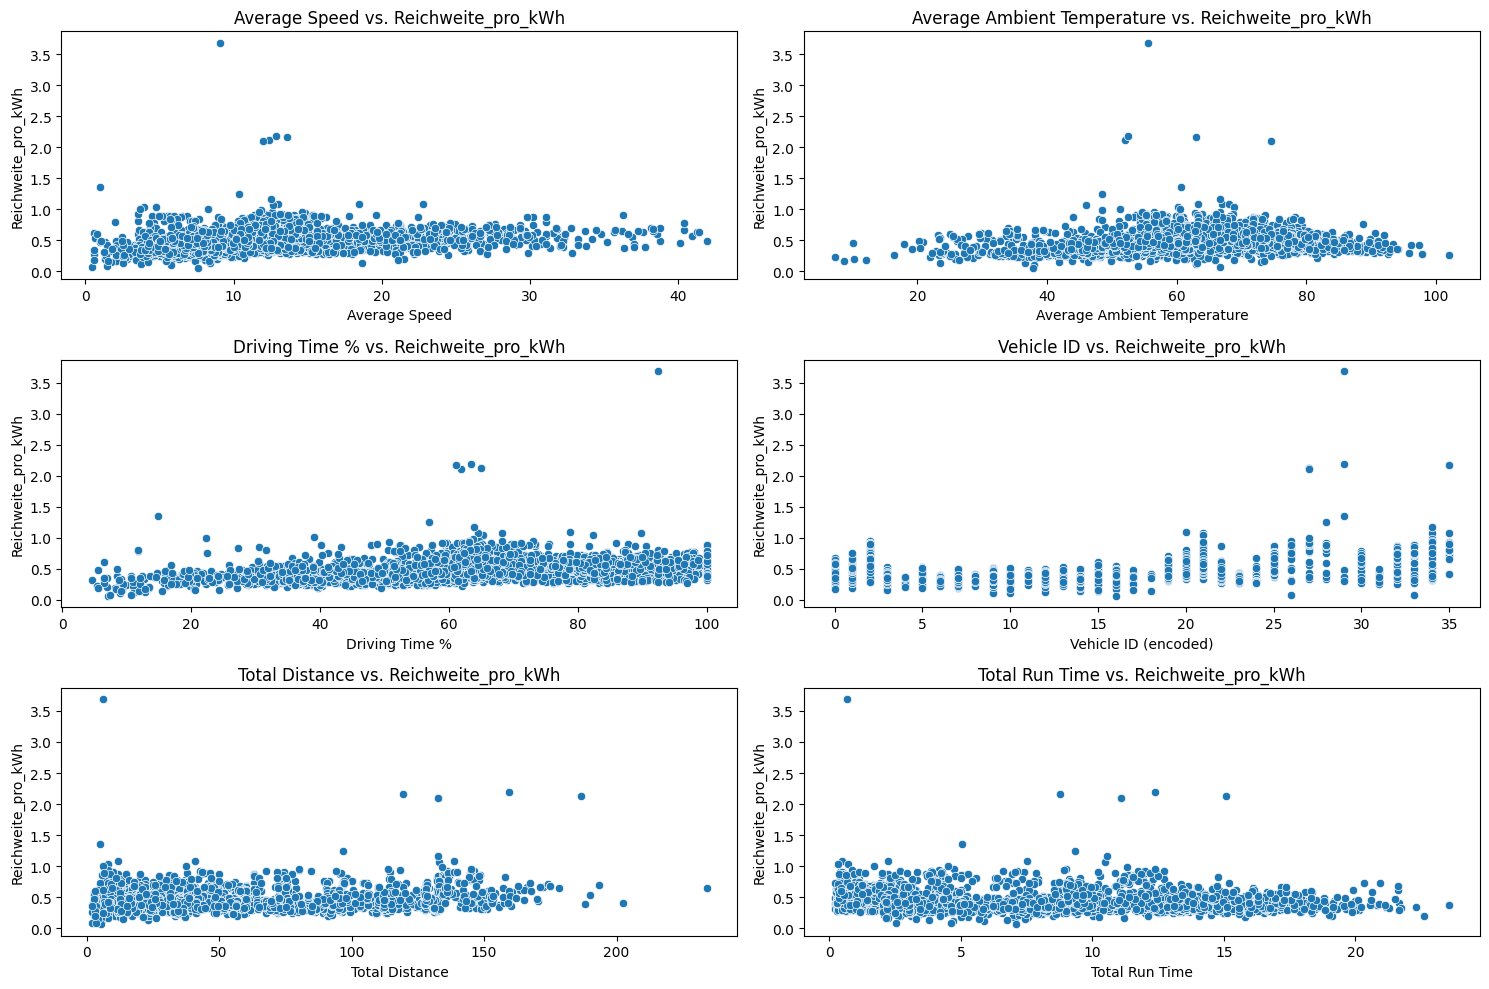

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Average Speed", ax=axes[0, 0])
axes[0, 0].set_title("Average Speed vs. Reichweite_pro_kWh")

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Average Ambient Temperature", ax=axes[0, 1])
axes[0, 1].set_title("Average Ambient Temperature vs. Reichweite_pro_kWh")

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Driving Time %", ax=axes[1, 0])
axes[1, 0].set_title("Driving Time % vs. Reichweite_pro_kWh")

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Vehicle ID (encoded)", ax=axes[1, 1])
axes[1, 1].set_title("Vehicle ID vs. Reichweite_pro_kWh")

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Total Run Time", ax=axes[2, 1])
axes[2, 1].set_title("Total Run Time vs. Reichweite_pro_kWh")

sns.scatterplot(data=df_s, y="Reichweite_pro_kWh", x="Total Distance", ax=axes[2, 0])
axes[2, 0].set_title("Total Distance vs. Reichweite_pro_kWh")


plt.tight_layout()
plt.show()

Erste Bemerkung: Unterschiedliche Fahrzeuge haben nicht den gleichen Energie-Verbrauch.

# Erstellung des Korelations-Heatmap

- Zielgröße und 5 andere Variablen
- "Total Distance" und "Total Energy Consumption" wurden in der Korelationsanalyse nicht betrachtet da die Reichweite direkt von den abhängt. 

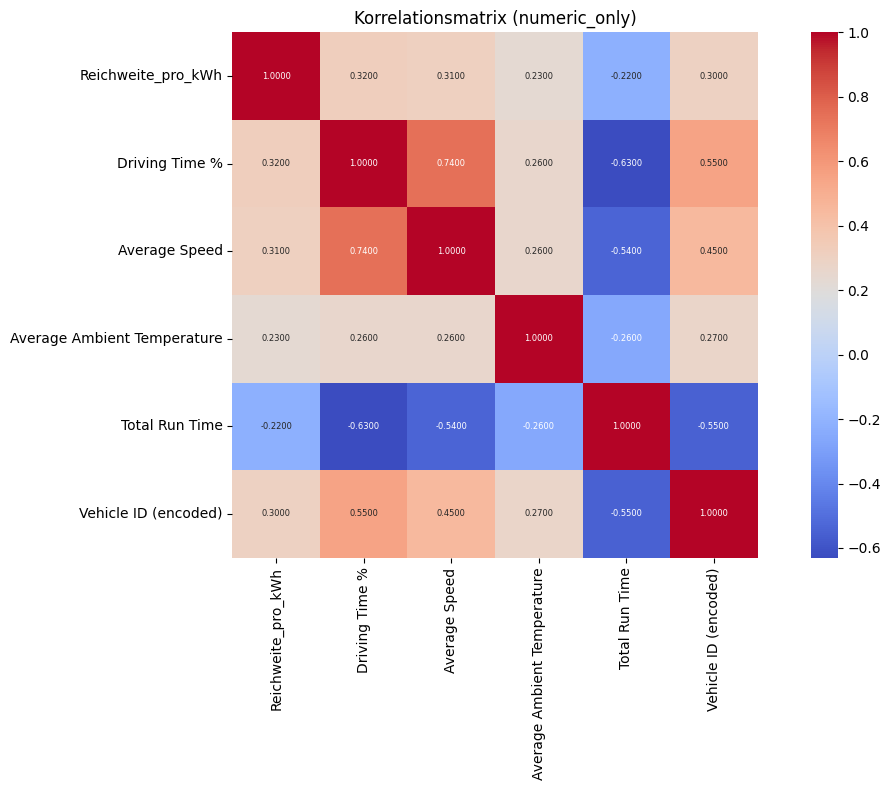

In [9]:

selectedforcorr = ["Reichweite_pro_kWh", "Driving Time %", "Average Speed", "Average Ambient Temperature","Total Run Time","Vehicle ID (encoded)"]

corr_matrix = df_s[selectedforcorr].corr().round(2)

# the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".4f", cmap="coolwarm",annot_kws={"size": 6}, square=True)

plt.title("Korrelationsmatrix (numeric_only)")
plt.tight_layout()
plt.show()

Hier werden die Ausreißer der Zielgröße dargestellt. Die Zielgröße Reichweite hängt von beiden Variablen "Total Distance" und "Total Energy Consumption" ab. Daher werden diese auch mitberücksichtigt

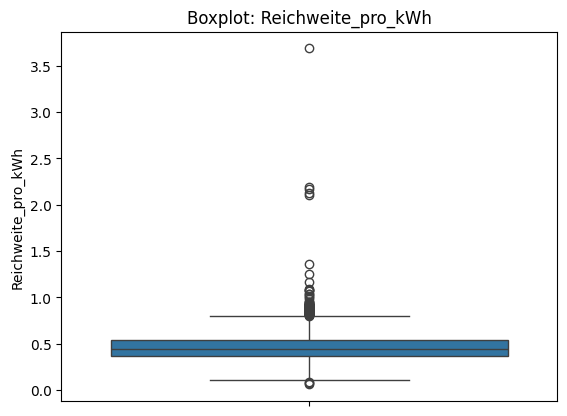

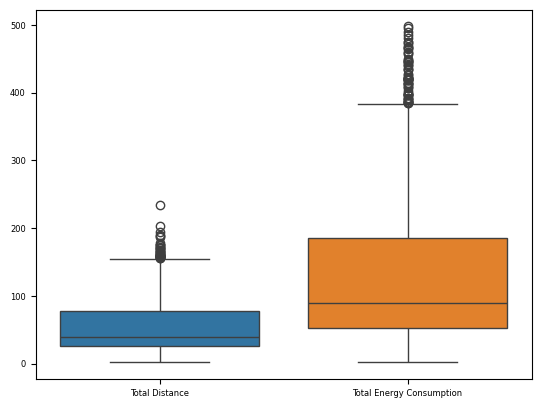

In [10]:
sns.boxplot(y=df_s["Reichweite_pro_kWh"])
plt.title("Boxplot: Reichweite_pro_kWh")
plt.show()

sns.boxplot(data=df_s[["Total Distance","Total Energy Consumption"]], orient="v")
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.show()

def get_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

outliers = get_outliers_iqr(df_s, "Reichweite_pro_kWh")
# print(outliers)

# Plausibilitätskontrolle Ausreißer bei weiteren Größen
- "Driving Time %": zwischen 0 und 100% -> alle Werte plausibel
- "Average Speed": zwischen 0 und 45 mph -> alle Werte plausibel
- "Average Ambient Temperature" -> Temperaturen in Farenheit liegen zw. 7 und 100 Grad bzw. zwischen -14°C und 39°C -> plausibel
- "Total Run Time" -> es konnte bis über 20 Stunden gemessen werden mit Betrachtung von Idle Time (Pausen) und dass mehrere Fahrerschichten gibt dann sind die Werte in Ordnung.

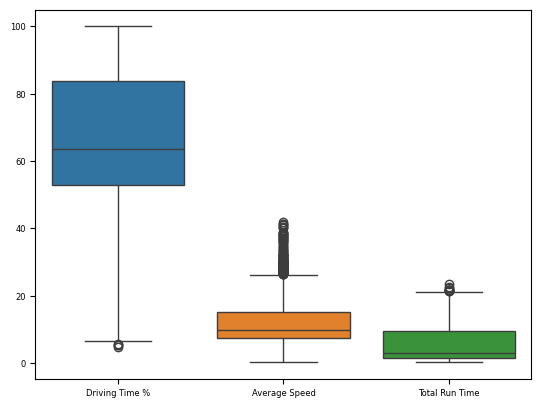

count    4001.000000
mean       60.852697
std        12.852307
min         7.252213
25%        52.430140
50%        61.480000
75%        69.620000
max       102.040784
Name: Average Ambient Temperature, dtype: float64

In [11]:
sns.boxplot(data=df_s[["Driving Time %", "Average Speed","Total Run Time"]], orient="v")
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.show()

df_s["Average Ambient Temperature"].describe()

wenn man längere Strecken fährt wird auch der Verbrauch höher. Es wurde bei der Datenvorarbeitung am Anfang extreme Werte wie 0 KWh Verbrauch gelöscht (Werte unter 1 KWh wurden imputiert) und über 500KWh für ein Tag ist extrem viel und wirkt unplausibl oder dass das Wagen einen Defekt hat. "Total Distance" Werte von unter 2 Meilen wurden auch nicht berücksichtigt damit es nicht schlecht auf die Werte der Reichweite schlecht auswirkt (Corner cases).

Ein Wichtiger Aspekt wäre noch anzuschauen ob den Anteil an reiner Fahrzeit oder die Durschnittliche Fahrgeschwindigkeit die Ausreißer in der Reichweite verursachen (z.B. wenn der Anteil an Fahrzeit sehr gering ist oder wenn zu langsam gefahren wird)

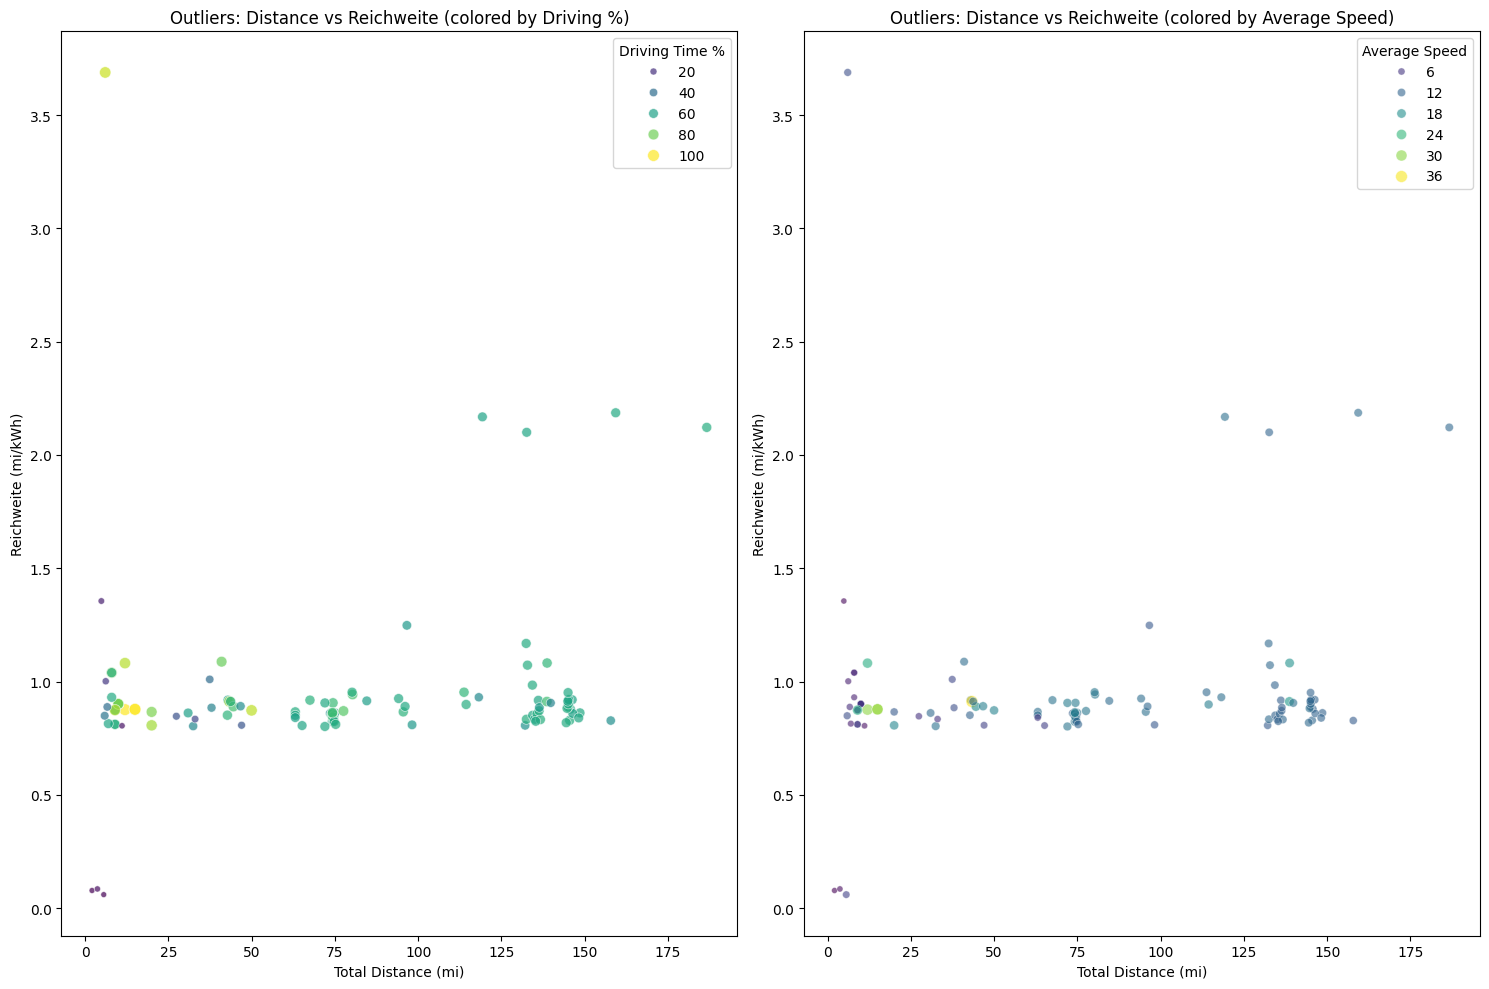

In [12]:
# Plot: Distance vs Reichweite, Driving %
fig, axes = plt.subplots(1, 2, figsize=(15, 10))

sns.scatterplot(
    data=outliers,
    x="Total Distance",
    y="Reichweite_pro_kWh",
    ax=axes[0],
    hue="Driving Time %",
    palette="viridis",
    size="Driving Time %",
    alpha=0.7
)
axes[0].set_title("Outliers: Distance vs Reichweite (colored by Driving %)")
axes[0].set_xlabel("Total Distance (mi)")
axes[0].set_ylabel("Reichweite (mi/kWh)")

# Plot: Distance vs Reichweite, Average Speed
sns.scatterplot(
    data=outliers,
    x="Total Distance",
    y="Reichweite_pro_kWh",
    hue="Average Speed",
    palette="viridis",
    size="Average Speed",
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Outliers: Distance vs Reichweite (colored by Average Speed)")
axes[1].set_xlabel("Total Distance (mi)")
axes[1].set_ylabel("Reichweite (mi/kWh)")

plt.tight_layout()
plt.show()



Man kann keine direkte Beziehung zwischen der "Average Speed" oder "Driving Time %" und die Außreißer der Reichweite feststellen.

Trotzdem werden die wenigen extremen Werten unterhalb 0,2 Meilen pro KWh und oberhalb 2 Meilen pro KWh imputiert und die restliche Outlier werden fuer das Trainieren des Modells trotzdem gelassen da diese immerhin plausibel sind.

In [13]:

df_m = df_s[(df_s["Reichweite_pro_kWh"] <= 2) & (df_s["Reichweite_pro_kWh"] >= 0.2)]

df_m.describe()



,Total Distance,Idling Time,Driving Time,Total Run Time,Initial SOC,Final SOC,SOC Used,Total Energy Consumption,Average Ambient Temperature,Initial Odometer,Final Odometer,Percent Idling Time,Average Speed,Vehicle ID (encoded),Reichweite_pro_kWh,Driving Time %
count,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000
mean,54.049143,2.620996,3.131900,5.752729,89.751621,68.295748,37.756985,125.906321,60.931620,7986.788784,8040.842992,2.591791,11.923116,15.464115,0.466102,66.142242
std,38.100844,3.009954,2.500566,5.196397,13.347723,20.185458,22.173995,96.327866,12.764508,5867.402228,5876.392449,9.803600,6.293425,8.844609,0.137555,20.041513
min,2.115769,0.000000,0.146253,0.200000,0.000000,4.145313,0.000000,3.615385,7.252213,3.190000,40.630000,0.000000,0.575004,0.000000,0.200263,4.658758
25%,26.137979,0.230000,1.250000,1.610000,85.663906,53.600000,21.195312,53.531506,52.500000,3515.500000,3561.368908,0.161057,7.538248,9.000000,0.369296,53.029167
50%,39.000000,1.397229,2.040000,3.070000,93.000000,69.600000,33.825000,89.100000,61.500000,6670.730434,6712.000000,0.379263,9.917202,19.000000,0.441176,63.749011
75%,77.803442,4.231500,5.032410,9.449277,100.000000,86.965625,50.800000,185.183423,69.638952,11211.000000,11252.783539,0.491697,15.075181,22.000000,0.541311,83.959742
max,234.023925,17.688455,11.813759,23.573715,100.000000,100.000000,168.481252,497.486400,102.040784,33706.824023,33756.766732,90.183518,41.950000,35.000000,1.355319,100.000000


One-hot encoding (Dummifizieren) für die Größe Vehicle ID

Dies verhindert Fehlinterpretationen durch numerische Kodierungen und macht die Daten modellkompatibel.

In [14]:
df_dummified = pd.get_dummies(df_m, columns=["Vehicle ID"], prefix="Vehicle", drop_first=False)


### Train-Test Split Begründung

Eine Testgröße von 0,2 wurde gewählt, was bedeutet, dass 80 % des Datensatzes zum Trainieren des Modells und 20 % zum Testen verwendet werden.  Dies ist ein allgemein üblicher Standard bei der Regressionsmodellierung. Da der Datensatz nur mäßig groß ist (ca. 4000 Zeilen), bietet eine Aufteilung von 20 % ein gutes Gleichgewicht zwischen der Robustheit des Modells und der Genauigkeit der Auswertung.

In [ ]:
# numeric features
num_feats = ["Driving Time %", "Average Speed", "Average Ambient Temperature", "Total Run Time"]

# dummified vehicle columns 
veh_feats = [c for c in df_dummified.columns if c.startswith("Vehicle_")]


X = df_dummified[num_feats + veh_feats]

#X = df_dummified[["Driving Time %", "Average Speed", "Average Ambient Temperature","Total Run Time","Vehicle ID (encoded)"]]
# Die Variante ohne Dummifizierung wurde auch ausprobiert, es wirkt sehr schlecht auf die LinearRegression wenn Integers ohne Dumifizierung genutzt werden 
# aber Die Variante ohne Dummifizierung hat leicht bessere Ergebnisse bei Decision Tree und Random Forest gezeigt -> Siehe die nächsten Snippets

y= df_dummified[["Reichweite_pro_kWh"]]


X= X.values.tolist()

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


Reichweite_pro_kWh wird vorhergesagt, was eine kontinuierliche Variable ist, daher ist die lineare Regression in der Tat die richtige Wahl.

# Linear Regression
- Model definition and fitting (Linear Regression)
- Model prediction
- Model evaluation via Mean Absolute Error, Mean Squared Error, and R squared Scroe
- Pipeline with scaling for comparison

Training Performance:
Train MAE: 0.05946448831866407
Train RMSE: 0.08492551225652228
Train R² Score: 0.6215501649351841

Testing Performance:
Test MAE: 0.05847110421140085
Test RMSE: 0.0820338679710898
Test R² Score: 0.6333247402453065


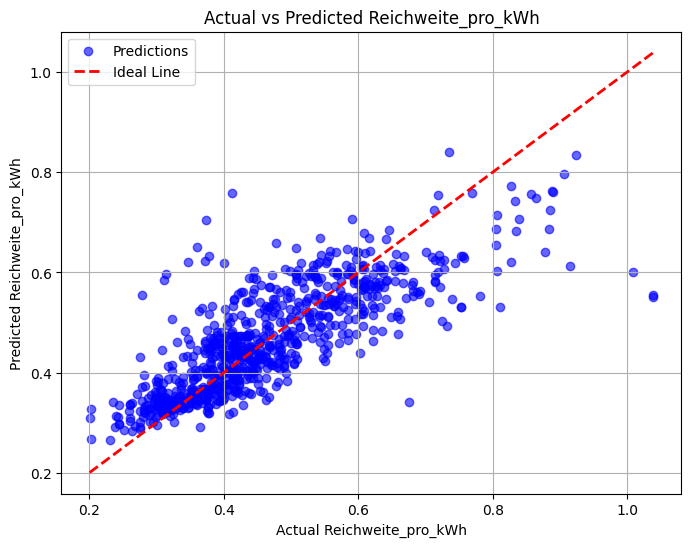


Pipeline Testing Performance:
Pipeline Test MAE: 0.05847110421140088
Pipeline Test MSE: 0.006729555494298193
Pipeline Test R² Score: 0.6333247402453065


In [ ]:
# Model definition and fitting (Linear Regression)
model = LinearRegression()
model.fit(X_train, y_train)


# Model prediction
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Training Performance:")
print("Train MAE:", mean_absolute_error(y_train, y_pred_train))
MSE= mean_squared_error(y_train, y_pred_train)
print("Train RMSE:", np.sqrt(MSE))
print("Train R² Score:", r2_score(y_train, y_pred_train))

print("\nTesting Performance:")
print("Test MAE:", mean_absolute_error(y_test, y_pred_test))
MSE_te= mean_squared_error(y_test, y_pred_test)
print("Test RMSE:", np.sqrt(MSE_te))
print("Test R² Score:", r2_score(y_test, y_pred_test))

# predictions vs actual values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_test, alpha=0.6, color='blue', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Line')
plt.xlabel("Actual Reichweite_pro_kWh")
plt.ylabel("Predicted Reichweite_pro_kWh")
plt.title("Actual vs Predicted Reichweite_pro_kWh")
plt.legend()
plt.grid(True)
plt.show()

# with scaling
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

pipeline.fit(X_train, y_train)

# evaluation
y_pred_pipeline = pipeline.predict(X_test)

print("\nPipeline Testing Performance:")
print("Pipeline Test MAE:", mean_absolute_error(y_test, y_pred_pipeline))
print("Pipeline Test MSE:", mean_squared_error(y_test, y_pred_pipeline))
print("Pipeline Test R² Score:", r2_score(y_test, y_pred_pipeline))


Pipeline (bzw. das Skalieren) hat die Funktionen  nicht geändert (nur die numerischen Variablen skaliert), daher bleiben die Vorhersagen unverändert.

# Decision Tree model
- Decision Tree definition and training
- Prediction on train and test data
- Evaluate Decision Tree model performance
- Visualization: Decision Tree predictions vs Actual values

Decision Tree Training Performance:
Train MAE: 0.06759338001635208
RMSE: 0.09633748239508533
Train R² Score: 0.5130071833027665

Decision Tree Testing Performance:
Test MAE: 0.07073242011834027
RMSE: 0.10055358849975651
Test R² Score: 0.4490776673941337


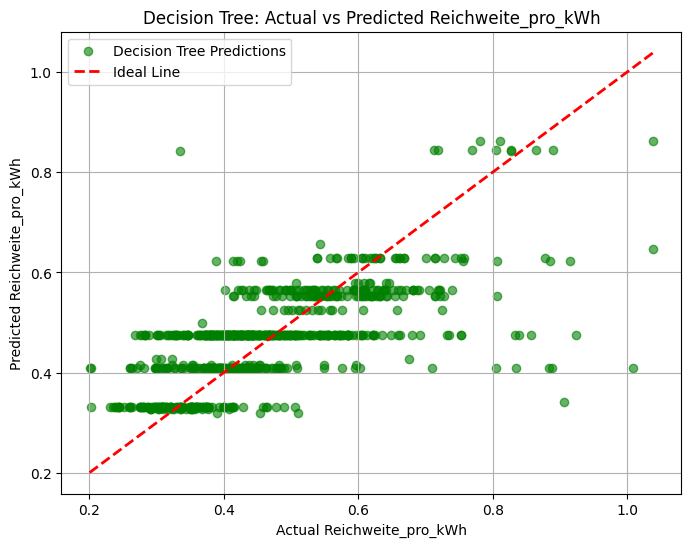

In [ ]:
# Decision Tree model definition and training
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train, y_train)

# Prediction on train and test data
y_pred_train_tree = tree_model.predict(X_train)
y_pred_test_tree = tree_model.predict(X_test)

# Evaluate Decision Tree model performance
print("Decision Tree Training Performance:")
print("Train MAE:", mean_absolute_error(y_train, y_pred_train_tree))
MSE=mean_squared_error(y_train, y_pred_train_tree)
print("RMSE:", np.sqrt(MSE))
print("Train R² Score:", r2_score(y_train, y_pred_train_tree))

print("\nDecision Tree Testing Performance:")
print("Test MAE:", mean_absolute_error(y_test, y_pred_test_tree))
MSE_te=mean_squared_error(y_test, y_pred_test_tree)
print("RMSE:", np.sqrt(MSE_te))
print("Test R² Score:", r2_score(y_test, y_pred_test_tree))

# Decision Tree predictions vs Actual values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_test_tree, alpha=0.6, color='green', label='Decision Tree Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Line')
plt.xlabel("Actual Reichweite_pro_kWh")
plt.ylabel("Predicted Reichweite_pro_kWh")
plt.title("Decision Tree: Actual vs Predicted Reichweite_pro_kWh")
plt.legend()
plt.grid(True)
plt.show()

# Random Forest model 
- Random Forest model definition and training
- Predictions on train and test data
- Evaluate Random Forest performance
- Visualization: Random Forest predictions vs Actual values

Random Forest Training Performance:
Train MAE: 0.0188656509645273
RMSE: 0.029361497683286122
Train R² Score: 0.9547635642374709

Random Forest Testing Performance:
Test MAE: 0.04965840417704076
RMSE: 0.07372663317386369
Test R² Score: 0.7038279762397098


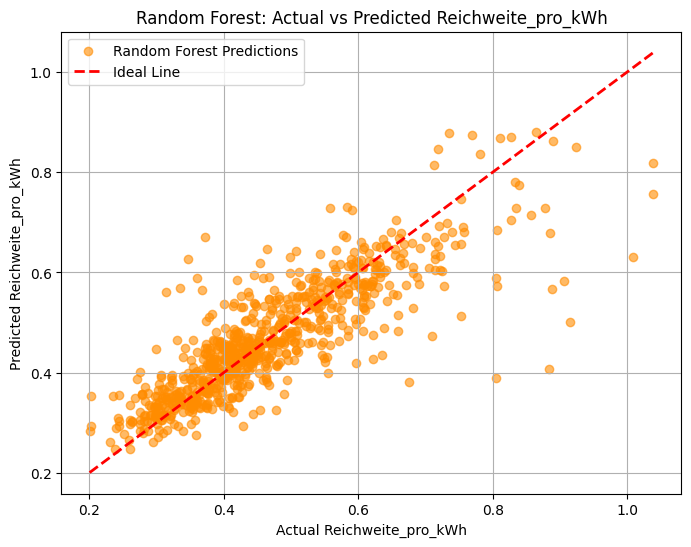

In [18]:
# Random Forest model definition and training
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions on train and test data
y_pred_train_rf = rf_model.predict(X_train)
y_pred_test_rf = rf_model.predict(X_test)

# Evaluate Random Forest performance
print("Random Forest Training Performance:")
print("Train MAE:", mean_absolute_error(y_train, y_pred_train_rf))
MSE=mean_squared_error(y_train, y_pred_train_rf)
print("RMSE:", np.sqrt(MSE))
print("Train R² Score:", r2_score(y_train, y_pred_train_rf))

print("\nRandom Forest Testing Performance:")
print("Test MAE:", mean_absolute_error(y_test, y_pred_test_rf))
MSE_te=mean_squared_error(y_test, y_pred_test_rf)
print("RMSE:", np.sqrt(MSE_te))
print("Test R² Score:", r2_score(y_test, y_pred_test_rf))

# Visualization: Random Forest predictions vs Actual values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_test_rf, alpha=0.6, color='darkorange', label='Random Forest Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Line')
plt.xlabel("Actual Reichweite_pro_kWh")
plt.ylabel("Predicted Reichweite_pro_kWh")
plt.title("Random Forest: Actual vs Predicted Reichweite_pro_kWh")
plt.legend()
plt.grid(True)
plt.show()

Man kann sehen, dass die Regression mit Random Forest den höchsten **R squared**-Wert aufweist. 

Hier wird versucht, die Variable „Vehicle ID“ gezielt nicht zu dumifizieren und sie als encoded Integer zu belassen, um zu sehen, ob dies zu besseren Ergebnissen führt. 35 zusätzliche Spalten für 36 Vehicle IDs können ein Effekt auf die Varianz haben. 

Random Forest Training Performance:
Train MAE: 0.018938366018521252
RMSE: 0.028737579629680647
Train R² Score: 0.9566656441443514

Random Forest Testing Performance:
Test MAE: 0.04797000782146068
RMSE: 0.06958947506494036
Test R² Score: 0.7361346580556387


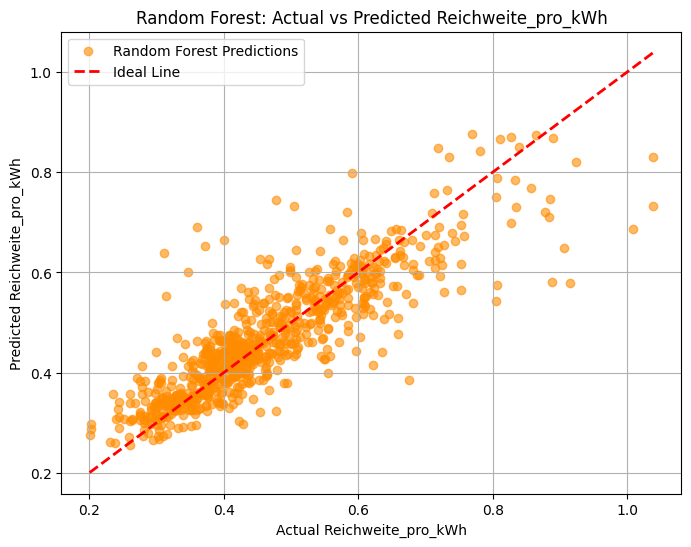

In [19]:
X = df_dummified[["Driving Time %", "Average Speed", "Average Ambient Temperature","Total Run Time","Vehicle ID (encoded)"]]

y= df_dummified[["Reichweite_pro_kWh"]]


X= X.values.tolist()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Random Forest model definition and training
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions on train and test data
y_pred_train_rf = rf_model.predict(X_train)
y_pred_test_rf = rf_model.predict(X_test)

# Evaluate Random Forest performance
print("Random Forest Training Performance:")
print("Train MAE:", mean_absolute_error(y_train, y_pred_train_rf))
MSE= mean_squared_error(y_train, y_pred_train_rf)
print("RMSE:", np.sqrt(MSE))
print("Train R² Score:", r2_score(y_train, y_pred_train_rf))

print("\nRandom Forest Testing Performance:")
print("Test MAE:", mean_absolute_error(y_test, y_pred_test_rf))
MSE_te= mean_squared_error(y_test, y_pred_test_rf)
print("RMSE:", np.sqrt(MSE_te))
print("Test R² Score:", r2_score(y_test, y_pred_test_rf))

# Visualization: Random Forest predictions vs Actual values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_test_rf, alpha=0.6, color='darkorange', label='Random Forest Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Line')
plt.xlabel("Actual Reichweite_pro_kWh")
plt.ylabel("Predicted Reichweite_pro_kWh")
plt.title("Random Forest: Actual vs Predicted Reichweite_pro_kWh")
plt.legend()
plt.grid(True)
plt.show()

Bei RandomForestRegressor erhöhte die One-Hot-Kodierung von Vehicle-ID die Dimensionalität. Dies erforderte mehrere Tree Splits, um dieselben Kategoriegruppierungen zu erfassen, und erhöhte die Varianz.  die nicht dummifizierte Version lieferte einen höheren Test-R Squared-Wert. 

- **Ziel**: Besseres Hyperparameter-Set finden: um Fehler (MAE/RMSE) zu sinken und **R squared** zu verbessern
- **Vorgehen im Code** : GridSearchCV 
   - Sucht über die Parameter: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` die beste Kombination.  
   - Liefert `best_estimator_`, der in der Cross-Validation den **geringsten RMSE** erzielt hat.

In [20]:


rf = RandomForestRegressor(random_state=42)

param_grid = {
    
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}   

grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("MAE:", mean_absolute_error(y_test, y_pred))
MSE=mean_squared_error(y_test, y_pred)
print("RMSE:", np.sqrt(MSE))
print("R² Score:", r2_score(y_test, y_pred))



Best Parameters: {'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}
MAE: 0.047476881537753805
RMSE: 0.06819872337274095
R² Score: 0.7465760127332313


# Bestes gefundene Modell 

MAE: 0.047476881537753805
RMSE: 0.06819872337274095
R² Score: 0.7465760127332313


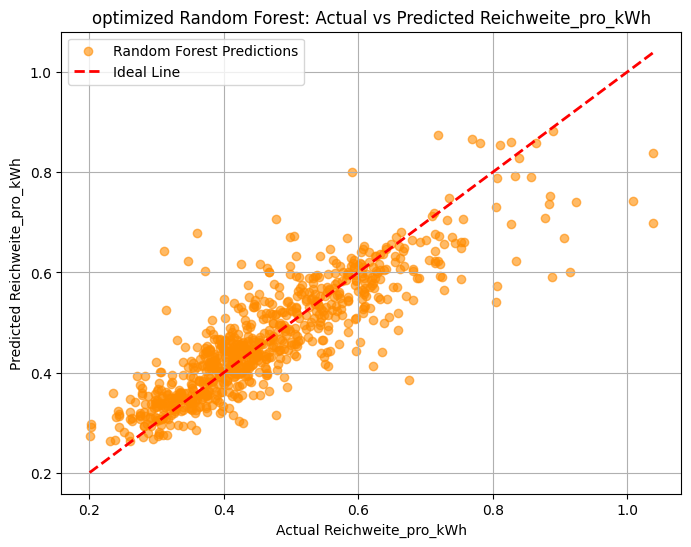

In [21]:
y = df_dummified["Reichweite_pro_kWh"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest (beste Parameter)
optimized_rf = RandomForestRegressor(
    max_depth=20, 
    min_samples_leaf=4, 
    min_samples_split=2, 
    n_estimators=200,
    random_state=42
)
optimized_rf.fit(X_train, y_train)

# Evaluation
y_pred_optimized = optimized_rf.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred_optimized))
MSE=mean_squared_error(y_test, y_pred_optimized)
print("RMSE:", np.sqrt(MSE))
print("R² Score:", r2_score(y_test, y_pred_optimized))

# Visualization: predictions vs Actual values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_optimized, alpha=0.6, color='darkorange', label='Random Forest Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Line')
plt.xlabel("Actual Reichweite_pro_kWh")
plt.ylabel("Predicted Reichweite_pro_kWh")
plt.title("optimized Random Forest: Actual vs Predicted Reichweite_pro_kWh")
plt.legend()
plt.grid(True)
plt.show()



### Out-of-sample prediction

Die prognoszierte Werte der Reichweite sind im plausiblen Bereich zwischen 0,32 Meilen/KWh bis 0,77 Meilen/KWh. Man sieht  dass wenn den Anteil an Fahrzeit höher ist (weniger Idle Time) und die Temperatur höher ist dann erhöht sich die Reichweite.

In [22]:
# Format: [Driving Time %, Average Speed in mph (Meilen pro Stunde), Avg Temp (Farenheit), Total Run Time (Stunden), Vehicle ID (encoded)]

X_external_1 = [[65.0, 22, 30, 9.0, 5]]     # Kalte Bedingungen, langsames Fahren, mittlere Fahrzeit
X_external_2 = [[80.0, 50, 96, 12.0, 2]]    # Warmes Wetter, hohe Geschwindigkeit, hohe Fahrzeit
X_external_3 = [[50.0, 27, 65, 6.5, 10]]    # Kürzere Fahrt, niedrige Geschwindigkeit, moderate Bedingungen
X_external_4 = [[90.0, 35, 65, 10.0, 3]]    # Sehr hoher Fahranteil, effiziente Bedingungen
X_external_5 = [[30.0, 35, 10, 5.0, 0]]     # Hauptsächlich Leerlauf, sehr niedrige Temperatur

for X_external in [X_external_1, X_external_2, X_external_3, X_external_4, X_external_5]:
    y_external_pred = optimized_rf.predict(X_external)
    print("\nPrediction for external data point:", y_external_pred)


Prediction for external data point: [0.3169004]

Prediction for external data point: [0.76749238]

Prediction for external data point: [0.4419517]

Prediction for external data point: [0.47885268]

Prediction for external data point: [0.48465487]
